In [18]:
import matplotlib.pyplot as pd_plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree

1. Load Dataset

In [19]:
print('--- Loading Dataset ---')
df = pd.read_csv('faculty_consultations.csv')
print(f'Dataset Shape: {df.shape}')
print(df.head())

--- Loading Dataset ---
Dataset Shape: (80, 7)
           Faculty     Day TimeSlot  StudentYear  Duration  CurrentBookings  \
0     Prof. Santos  Monday    15:00            3        30                0   
1  Prof. Dela Rosa  Monday    14:00            4        15                0   
2  Prof. Dela Rosa  Friday     9:00            2        60                1   
3       Prof. Cruz  Monday    10:00            4        30                0   
4       Prof. Cruz  Monday     9:00            4        15                1   

  SlotAvailable  
0           Yes  
1           Yes  
2            No  
3           Yes  
4           Yes  


2. Preprocessing and Categorical Encoding

In [20]:
le_faculty = LabelEncoder()
le_day = LabelEncoder()
le_time = LabelEncoder()

df['Faculty_Encoded'] = le_faculty.fit_transform(df['Faculty'])
df['Day_Encoded'] = le_day.fit_transform(df['Day'])
df['TimeSlot_Encoded'] = le_time.fit_transform(df['TimeSlot'])

# target variable mapping: 'Yes' = 1 (Available), 'No' = 0 (Unavailable)
df['Target'] = df['SlotAvailable'].apply(
    lambda x: 1 if str(x).strip().capitalize() == 'Yes' else 0
)

# define feature matrix (X) and target vector (y)
X = df[
    [
        'Faculty_Encoded',
        'Day_Encoded',
        'TimeSlot_Encoded',
        'StudentYear',
        'Duration',
        'CurrentBookings',
    ]
]
y = df['Target']

# split data (70% Training, 30% Testing)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

3. Primary Algorithm (Decision Tree Classifier)

In [21]:
print('\n--- Training Primary Model: Decision Tree ---')
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)
dt_preds = dt_model.predict(X_test)


--- Training Primary Model: Decision Tree ---


4. Comparison Algorithm (Logistics Regression)

In [22]:
print('--- Training Comparison Model: Logistic Regression ---')
lr_model = LogisticRegression(max_iter=500)
lr_model.fit(X_train, y_train)
lr_preds = lr_model.predict(X_test)

--- Training Comparison Model: Logistic Regression ---


5. Evaluate and print metrics

In [23]:
dt_acc = accuracy_score(y_test, dt_preds)
lr_acc = accuracy_score(y_test, lr_preds)

print('\n================ RESULTS COMPARISON ================')
print(f'Decision Tree Accuracy     : {dt_acc * 100:.2f}%')
print(f'Logistic Regression Accuracy: {lr_acc * 100:.2f}%')

print('\nDecision Tree Confusion Matrix (TN, FP, FN, TP):')
print(confusion_matrix(y_test, dt_preds))

print('\nDecision Tree Classification Report:')
print(classification_report(y_test, dt_preds))

print('Logistic Regression Classification Report:')
print(classification_report(y_test, lr_preds))


================ RESULTS COMPARISON ================
Decision Tree Accuracy     : 87.50%
Logistic Regression Accuracy: 83.33%

Decision Tree Confusion Matrix (TN, FP, FN, TP):
[[ 9  1]
 [ 2 12]]

Decision Tree Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.90      0.86        10
           1       0.92      0.86      0.89        14

    accuracy                           0.88        24
   macro avg       0.87      0.88      0.87        24
weighted avg       0.88      0.88      0.88        24

Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.90      0.82        10
           1       0.92      0.79      0.85        14

    accuracy                           0.83        24
   macro avg       0.83      0.84      0.83        24
weighted avg       0.85      0.83      0.83        24



6. Feature importance visualization

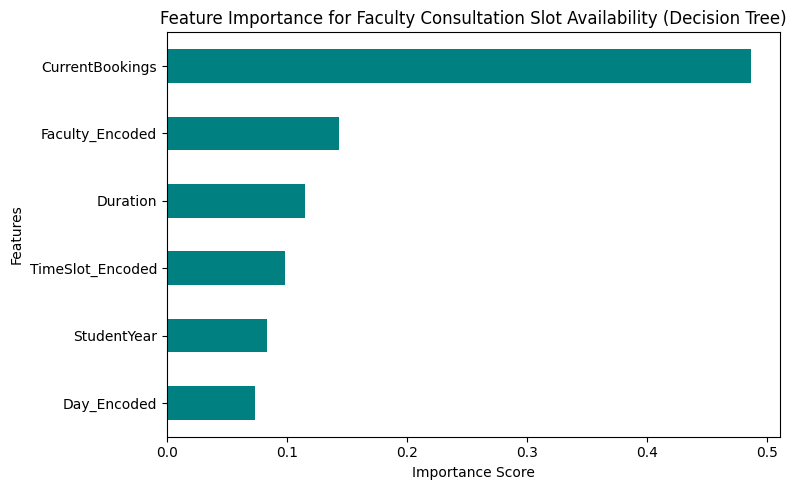

In [25]:
plt.figure(figsize=(8, 5))
feature_importances = pd.Series(
    dt_model.feature_importances_, index=X.columns
).sort_values(ascending=True)
feature_importances.plot(kind='barh', color='teal')
plt.title(
    'Feature Importance for Faculty Consultation Slot Availability (Decision'
    ' Tree)'
)
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()